## Data loading

Load the compressed Steam game, review, and user-item files into separate dataframes, then preview a few rows from each.

In [1]:
import ast
import gzip
import pandas as pd
from pathlib import Path

DATA_DIR = Path("dataset")

def load_data(filename):
    with gzip.open(DATA_DIR / filename, "rt", encoding="utf-8") as f:
        return pd.DataFrame(ast.literal_eval(line) for line in f if line.strip())

games = load_data("steam_games.json.gz")
reviews_raw = load_data("australian_user_reviews.json.gz")
user_items_raw = load_data("australian_users_items.json.gz")

display(games.head(5))
display(reviews_raw.head(5))
display(user_items_raw.head(5))

,publisher,genres,app_name,title,url,release_date,tags,discount_price,reviews_url,specs,price,early_access,id,developer,sentiment,metascore
0,Kotoshiro,"[Action, Casual, Indie, Simulation, Strategy]",Lost Summoner Kitty,Lost Summoner Kitty,http://store.steampowered.com/app/761140/Lost_...,2018-01-04,"[Strategy, Action, Indie, Casual, Simulation]",4.49,http://steamcommunity.com/app/761140/reviews/?...,[Single-player],4.99,False,761140,Kotoshiro,NaN,NaN
1,"Making Fun, Inc.","[Free to Play, Indie, RPG, Strategy]",Ironbound,Ironbound,http://store.steampowered.com/app/643980/Ironb...,2018-01-04,"[Free to Play, Strategy, Indie, RPG, Card Game...",NaN,http://steamcommunity.com/app/643980/reviews/?...,"[Single-player, Multi-player, Online Multi-Pla...",Free To Play,False,643980,Secret Level SRL,Mostly Positive,NaN
2,Poolians.com,"[Casual, Free to Play, Indie, Simulation, Sports]",Real Pool 3D - Poolians,Real Pool 3D - Poolians,http://store.steampowered.com/app/670290/Real_...,2017-07-24,"[Free to Play, Simulation, Sports, Casual, Ind...",NaN,http://steamcommunity.com/app/670290/reviews/?...,"[Single-player, Multi-player, Online Multi-Pla...",Free to Play,False,670290,Poolians.com,Mostly Positive,NaN
3,彼岸领域,"[Action, Adventure, Casual]",弹炸人2222,弹炸人2222,http://store.steampowered.com/app/767400/2222/,2017-12-07,"[Action, Adventure, Casual]",0.83,http://steamcommunity.com/app/767400/reviews/?...,[Single-player],0.99,False,767400,彼岸领域,NaN,NaN
4,NaN,NaN,Log Challenge,NaN,http://store.steampowered.com/app/773570/Log_C...,NaN,"[Action, Indie, Casual, Sports]",1.79,http://steamcommunity.com/app/773570/reviews/?...,"[Single-player, Full controller support, HTC V...",2.99,False,773570,NaN,NaN,NaN


,user_id,user_url,reviews
0,76561197970982479,http://steamcommunity.com/profiles/76561197970...,"[{'funny': '', 'posted': 'Posted November 5, 2..."
1,js41637,http://steamcommunity.com/id/js41637,"[{'funny': '', 'posted': 'Posted June 24, 2014..."
2,evcentric,http://steamcommunity.com/id/evcentric,"[{'funny': '', 'posted': 'Posted February 3.',..."
3,doctr,http://steamcommunity.com/id/doctr,"[{'funny': '', 'posted': 'Posted October 14, 2..."
4,maplemage,http://steamcommunity.com/id/maplemage,"[{'funny': '3 people found this review funny',..."


,user_id,items_count,steam_id,user_url,items
0,76561197970982479,277,76561197970982479,http://steamcommunity.com/profiles/76561197970...,"[{'item_id': '10', 'item_name': 'Counter-Strik..."
1,js41637,888,76561198035864385,http://steamcommunity.com/id/js41637,"[{'item_id': '10', 'item_name': 'Counter-Strik..."
2,evcentric,137,76561198007712555,http://steamcommunity.com/id/evcentric,"[{'item_id': '1200', 'item_name': 'Red Orchest..."
3,Riot-Punch,328,76561197963445855,http://steamcommunity.com/id/Riot-Punch,"[{'item_id': '10', 'item_name': 'Counter-Strik..."
4,doctr,541,76561198002099482,http://steamcommunity.com/id/doctr,"[{'item_id': '300', 'item_name': 'Day of Defea..."


Compare each raw dataframe’s dimensions, column types, and non-null counts to understand the available data.

In [2]:
datasets_raw = {
    "games": games,
    "reviews_raw": reviews_raw,
    "user_items_raw": user_items_raw,
}

for name, df in datasets_raw.items():
    print(f"\n{'=' * 65}")
    print(f"{name.upper()}: {df.shape}")
    print("=" * 65)

    print("\nData types:")
    print(df.info())


GAMES: (32135, 16)

Data types:
<class 'pandas.DataFrame'>
RangeIndex: 32135 entries, 0 to 32134
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   publisher       24083 non-null  str    
 1   genres          28852 non-null  object 
 2   app_name        32133 non-null  str    
 3   title           30085 non-null  str    
 4   url             32135 non-null  str    
 5   release_date    30068 non-null  str    
 6   tags            31972 non-null  object 
 7   discount_price  225 non-null    float64
 8   reviews_url     32133 non-null  str    
 9   specs           31465 non-null  object 
 10  price           30758 non-null  object 
 11  early_access    32135 non-null  bool   
 12  id              32133 non-null  str    
 13  developer       28836 non-null  str    
 14  sentiment       24953 non-null  str    
 15  metascore       2677 non-null   object 
dtypes: bool(1), float64(1), object(5), str(9)
memory usage

## Checking missing

Measure missing values per column in all raw datasets and flag columns with at least 10% missingness.

In [3]:
missing_info = {}
t = 0.10

for name, df in datasets_raw.items():
    missing = pd.DataFrame({
        "missing_n": df.isna().sum(),
        "missing_%": (df.isna().mean() * 100).round(2)
    })

    missing_info[name] = {
        "missing": missing,
        "missing_cols": df.columns[df.isna().mean() >= t].tolist()
    }

    print(f"\n{'=' * 65}")
    print(f"{name.upper()}: {df.shape}")
    print("=" * 65)
    print("\nMissing values:")

    display(missing.sort_values("missing_%", ascending=False))



GAMES: (32135, 16)

Missing values:


,missing_n,missing_%
discount_price,31910,99.30
metascore,29458,91.67
publisher,8052,25.06
sentiment,7182,22.35
developer,3299,10.27
genres,3283,10.22
release_date,2067,6.43
title,2050,6.38
price,1377,4.29
specs,670,2.08



REVIEWS_RAW: (25799, 3)

Missing values:


,missing_n,missing_%
user_id,0,0.0
user_url,0,0.0
reviews,0,0.0



USER_ITEMS_RAW: (88310, 5)

Missing values:


,missing_n,missing_%
user_id,0,0.0
items_count,0,0.0
steam_id,0,0.0
user_url,0,0.0
items,0,0.0


List the game columns above the missingness threshold and inspect their raw values.

In [4]:
print(missing_info["games"]["missing_cols"])
games[missing_info["games"]["missing_cols"]]

['publisher', 'genres', 'discount_price', 'developer', 'sentiment', 'metascore']


,publisher,genres,discount_price,developer,sentiment,metascore
0,Kotoshiro,"[Action, Casual, Indie, Simulation, Strategy]",4.49,Kotoshiro,NaN,NaN
1,"Making Fun, Inc.","[Free to Play, Indie, RPG, Strategy]",NaN,Secret Level SRL,Mostly Positive,NaN
2,Poolians.com,"[Casual, Free to Play, Indie, Simulation, Sports]",NaN,Poolians.com,Mostly Positive,NaN
3,彼岸领域,"[Action, Adventure, Casual]",0.83,彼岸领域,NaN,NaN
4,NaN,NaN,1.79,NaN,NaN,NaN
...,...,...,...,...,...,...
32130,Ghost_RUS Games,"[Casual, Indie, Simulation, Strategy]",1.49,"Nikita ""Ghost_RUS""",NaN,NaN
32131,Sacada,"[Casual, Indie, Strategy]",4.24,Sacada,NaN,NaN
32132,Laush Studio,"[Indie, Racing, Simulation]",1.39,Laush Dmitriy Sergeevich,NaN,NaN
32133,SIXNAILS,"[Casual, Indie]",NaN,"xropi,stev3ns",1 user reviews,NaN


Count distinct non-missing values and calculate missing percentages for the selected game columns.

In [5]:
to_check_unique = missing_info["games"]["missing_cols"] + ["price"]

for col in to_check_unique:
    print(f"\n{'=' * 50}")
    print(col.upper())
    print(f"{'=' * 50}")

    values = games[col].explode().dropna().unique() if col == "genres" else games[col].dropna().unique()
    unique_count = len(values)
    missing_count = games[col].isna().sum()
    # unique_to_missing_ratio = unique_count / missing_count if missing_count else float("nan")
    missing_pct = games[col].isna().mean() * 100

    print(f"Unique values: {unique_count}")
    print(f"Missing values: {missing_count}")
    # print(f"Unique-to-missing ratio: {unique_to_missing_ratio:.4f}")
    print(f"Missing percentage: {missing_pct:.2f}%")
    display(values)


PUBLISHER
Unique values: 8239
Missing values: 8052
Missing percentage: 25.06%


<StringArray>
[                     'Kotoshiro',               'Making Fun, Inc.',
                   'Poolians.com',                           '彼岸领域',
            'Trickjump Games Ltd',         'Poppermost Productions',
                      'RewindApp',                        'Qucheza',
 'Stegalosaurus Game Development',              'Copperpick Studio',
 ...
                   'Enkian Games',                'Chadams Studios',
                      'YAOYICHEN',                   '杭州分浪网络科技有限公司',
                     'KUMA GAMES',                      'Fred Ells',
                        'VersoVR',             'OrtiGames/OrtiSoft',
                         'INGAME',                'Bidoniera Games']
Length: 8239, dtype: str


GENRES
Unique values: 22
Missing values: 3283
Missing percentage: 10.22%


<StringArray>
[                   'Action',                    'Casual',
                     'Indie',                'Simulation',
                  'Strategy',              'Free to Play',
                       'RPG',                    'Sports',
                 'Adventure',                    'Racing',
              'Early Access',     'Massively Multiplayer',
  'Animation &amp; Modeling',          'Video Production',
                 'Utilities',            'Web Publishing',
                 'Education',         'Software Training',
 'Design &amp; Illustration',          'Audio Production',
             'Photo Editing',                'Accounting']
Length: 22, dtype: str


DISCOUNT_PRICE
Unique values: 82
Missing values: 31910
Missing percentage: 99.30%


...

<StringArray>
[        'Mostly Positive',                   'Mixed',
          '1 user reviews',          '3 user reviews',
          '8 user reviews',           'Very Positive',
 'Overwhelmingly Positive',          '6 user reviews',
          '5 user reviews',          '2 user reviews',
           'Very Negative',                'Positive',
         'Mostly Negative',          '9 user reviews',
                'Negative',          '4 user reviews',
          '7 user reviews', 'Overwhelmingly Negative']
Length: 18, dtype: str


METASCORE
Unique values: 71
Missing values: 29458
Missing percentage: 91.67%


array([96, 84, 80, 76, 70, 'NA', 69, 81, 75, 72, 66, 67, 77, 91, 89, 83,
       61, 88, 65, 94, 57, 86, 87, 92, 79, 82, 58, 74, 85, 90, 68, 71, 60,
       73, 59, 64, 54, 53, 78, 51, 44, 63, 38, 56, 49, 52, 62, 93, 48, 34,
       95, 43, 55, 24, 46, 41, 20, 39, 45, 35, 47, 40, 36, 50, 32, 37, 33,
       42, 27, 29, 30], dtype=object)


PRICE
Unique values: 162
Missing values: 1377
Missing percentage: 4.29%


array([4.99, 'Free To Play', 'Free to Play', 0.99, 2.99, 3.99, 9.99,
       18.99, 29.99, 'Free', 10.99, 1.59, 14.99, 1.99, 59.99, 8.99, 6.99,
       7.99, 39.99, 19.99, 7.49, 12.99, 5.99, 2.49, 15.99, 1.25, 24.99,
       17.99, 61.99, 3.49, 11.99, 13.99, 'Free Demo', 'Play for Free!',
       34.99, 74.76, 1.49, 32.99, 99.99, 14.95, 69.99, 16.99, 79.99,
       49.99, 5.0, 44.99, 13.98, 29.96, 119.99, 109.99, 149.99, 771.71,
       'Install Now', 21.99, 89.99, 'Play WARMACHINE: Tactics Demo', 0.98,
       139.92, 4.29, 64.99, 'Free Mod', 54.99, 74.99, 'Install Theme',
       0.89, 'Third-party', 0.5, 'Play Now', 299.99, 1.29, 3.0, 15.0,
       5.49, 23.99, 49.0, 20.99, 10.93, 1.39, 'Free HITMAN™ Holiday Pack',
       36.99, 4.49, 2.0, 4.0, 9.0, 234.99, 1.95, 1.5, 199.0, 189.0, 6.66,
       27.99, 10.49, 129.99, 179.0, 26.99, 399.99, 31.99, 399.0, 20.0,
       40.0, 3.33, 199.99, 22.99, 320.0, 38.85, 71.7, 59.95, 995.0, 27.49,
       3.39, 6.0, 19.95, 499.99, 16.06, 4.68, 131.4, 44.98, 2

Create independent working copies so cleaning operations do not alter the raw datasets.

In [151]:
games_clean = games.copy()
reviews_clean = reviews_raw.copy()
user_items_clean = user_items_raw.copy()

clean_datasets = [
    ("games_clean", games_clean),
    ("reviews_clean", reviews_clean),
    ("user_items_clean", user_items_clean),
]

Normalize game sentiment and price values, fill unknown publisher/developer names, and drop irrelevant or highly incomplete columns.

In [59]:
# CLEANING SENTIMENT COLUMN
sentiment_map = {
    "Overwhelmingly Negative": 1,
    "Very Negative": 2,
    "Negative": 3,
    "Mostly Negative": 4,
    "Mixed": 5,
    "Mostly Positive": 6,
    "Positive": 7,
    "Very Positive": 8,
    "Overwhelmingly Positive": 9
}

games_clean["sentiment"] = (
    games_clean["sentiment"]
    .replace(r"^\d+ user reviews$", 0, regex=True)
    .map(sentiment_map)
    .fillna(0)
    .astype("Int64")
)

# CLEANING PRICE COLUMN
free_values = [
    "Free",
    "Free To Play",
    "Free to Play",
    "Free Demo",
    "Play for Free!",
    "Free Mod",
    "Free HITMAN™ Holiday Pack",
    "Free to Try",
    "Free Movie",
    "Free to Use"
]

games_clean["price"] = games_clean["price"].replace(free_values, 0)
games_clean["price"] = pd.to_numeric(games_clean["price"], errors="coerce")

# CLEANING PUBLISHER AND DEVELOPER COLUMNS
games_clean[["publisher", "developer"]] = (
    games_clean[["publisher", "developer"]]
    .fillna("Unknown")
)

# DROP IRRELEVANT OR REDUNDANT COLUMNS
games_clean.drop(
    columns=[
        "title",           # same and not as complete as "app_name"
        "discount_price",  # too much NA
        "metascore",       # too much NA
        "genres",          # same and not as complete as "tags"
        "url",             # irrelevant for analysis
        "reviews_url"      # irrelevant for analysis
    ],
    inplace=True
)


Recheck missing values in the cleaned games data and identify any remaining columns above the 10% threshold.

In [60]:
# Check for missing values in the cleaned datasets with the same threshold

t = 0.10

missing = pd.DataFrame({
    "missing_n": games_clean.isna().sum(),
    "missing_%": (games_clean.isna().mean() * 100).round(2)
})

missing_info = {
    "missing": missing,
    "missing_cols": games_clean.columns[games_clean.isna().mean() >= t].tolist()
}

print(f"\n{'=' * 65}")
print(f"GAMES: {games_clean.shape}")
print("=" * 65)
print("\nMissing values:")

display(games_clean.info())
display(missing.sort_values("missing_%", ascending=False))



GAMES: (32135, 10)

Missing values:
<class 'pandas.DataFrame'>
RangeIndex: 32135 entries, 0 to 32134
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   publisher     32135 non-null  str    
 1   app_name      32133 non-null  str    
 2   release_date  30068 non-null  str    
 3   tags          31972 non-null  object 
 4   specs         31465 non-null  object 
 5   price         30748 non-null  float64
 6   early_access  32135 non-null  bool   
 7   id            32133 non-null  str    
 8   developer     32135 non-null  str    
 9   sentiment     32135 non-null  Int64  
dtypes: Int64(1), bool(1), float64(1), object(2), str(5)
memory usage: 2.3+ MB


None

,missing_n,missing_%
release_date,2067,6.43
price,1387,4.32
specs,670,2.08
tags,163,0.51
id,2,0.01
app_name,2,0.01
publisher,0,0.00
early_access,0,0.00
developer,0,0.00
sentiment,0,0.00


Remove rows with remaining missing values from the games dataframe and report how much of the raw data remains.

In [61]:
games_clean.dropna(inplace=True)

print(f"Retained {len(games_clean) / len(games) * 100:.2f}% of the raw data")
display(games_clean)

Retained 87.24% of the raw data


,publisher,app_name,release_date,tags,specs,price,early_access,id,developer,sentiment
0,Kotoshiro,Lost Summoner Kitty,2018-01-04,"[Strategy, Action, Indie, Casual, Simulation]",[Single-player],4.99,False,761140,Kotoshiro,0
1,"Making Fun, Inc.",Ironbound,2018-01-04,"[Free to Play, Strategy, Indie, RPG, Card Game...","[Single-player, Multi-player, Online Multi-Pla...",0.00,False,643980,Secret Level SRL,6
2,Poolians.com,Real Pool 3D - Poolians,2017-07-24,"[Free to Play, Simulation, Sports, Casual, Ind...","[Single-player, Multi-player, Online Multi-Pla...",0.00,False,670290,Poolians.com,6
3,彼岸领域,弹炸人2222,2017-12-07,"[Action, Adventure, Casual]",[Single-player],0.99,False,767400,彼岸领域,0
5,Trickjump Games Ltd,Battle Royale Trainer,2018-01-04,"[Action, Adventure, Simulation, FPS, Shooter, ...","[Single-player, Steam Achievements]",3.99,False,772540,Trickjump Games Ltd,5
...,...,...,...,...,...,...,...,...,...,...
32129,Bidoniera Games,Kebab it Up!,2018-01-04,"[Action, Indie, Casual, Violent, Adventure]","[Single-player, Steam Achievements, Steam Cloud]",1.99,False,745400,Bidoniera Games,0
32130,Ghost_RUS Games,Colony On Mars,2018-01-04,"[Strategy, Indie, Casual, Simulation]","[Single-player, Steam Achievements]",1.99,False,773640,"Nikita ""Ghost_RUS""",0
32131,Sacada,LOGistICAL: South Africa,2018-01-04,"[Strategy, Indie, Casual]","[Single-player, Steam Achievements, Steam Clou...",4.99,False,733530,Sacada,0
32132,Laush Studio,Russian Roads,2018-01-04,"[Indie, Simulation, Racing]","[Single-player, Steam Achievements, Steam Trad...",1.99,False,610660,Laush Dmitriy Sergeevich,0


Summarize the cleaned games data and inspect the ten highest-priced entries.

In [62]:
display(games_clean.describe())
display(games_clean.sort_values("price", ascending=False).head(10))

,price,sentiment
count,28033.000000,28033.0
mean,8.592957,3.090179
std,14.567068,3.324253
min,0.000000,0.0
25%,2.990000,0.0
50%,4.990000,0.0
75%,9.990000,6.0
max,995.000000,9.0


,publisher,app_name,release_date,tags,specs,price,early_access,id,developer,sentiment
12088,"Strata Mixed Reality, Inc.",Strata Spaces VR – Professional Edition Upgrade,2017-10-26,"[Design & Illustration, Animation & Modeling]","[Downloadable Content, Steam Achievements, Ste...",995.00,False,719000,"Strata Mixed Reality, Inc.",0
2392,Aerosoft GmbH,X-Plane 10 Global - 64 Bit,2014-07-14,"[Simulation, Flight, Realistic, Open World, Mu...","[Single-player, Multi-player, Cross-Platform M...",771.71,False,292180,Laminar Research,5
14304,RUHRSOURCE GmbH,CUR3D Maker Edition - Permission for commercia...,2017-11-06,"[Utilities, Design & Illustration, Animation &...",[Downloadable Content],499.99,False,691560,RUHRSOURCE GmbH,0
17794,CCP,EVE Online: 15400 PLEX,2017-05-09,"[Free to Play, RPG, Massively Multiplayer]","[Online Multi-Player, MMO, Downloadable Conten...",499.99,False,629796,CCP,0
9075,YoYo Games Ltd.,GameMaker Studio 2 UWP,2017-03-08,"[Game Development, Design & Illustration, Util...",[In-App Purchases],399.99,False,585610,YoYo Games Ltd.,0
9074,YoYo Games Ltd.,GameMaker Studio 2 Mobile,2017-03-08,"[Game Development, Design & Illustration, Anim...",[In-App Purchases],399.99,False,585620,YoYo Games Ltd.,0
4445,The Foundry,MODO indie 10,2015-09-24,"[Animation & Modeling, Design & Illustration]",[Steam Cloud],299.99,False,401090,The Foundry,6
29566,Clickteam,Clickteam Fusion 2.5 Developer Upgrade,2014-01-27,"[Utilities, Animation & Modeling, Education, W...","[Single-player, Multi-player, MMO, Co-op, Shar...",299.99,False,267810,Clickteam,0
26852,Ambiera e.U.,CopperCube - Professional Edition,2015-04-24,"[Design & Illustration, Utilities, Animation &...","[Single-player, Downloadable Content, Stats, I...",289.99,False,366190,Ambiera e.U.,0
17793,CCP,EVE Online: 7430 PLEX,2017-05-09,"[Free to Play, RPG, Massively Multiplayer]","[Online Multi-Player, MMO, Downloadable Conten...",249.99,False,629795,CCP,0


some games have different or no prices (checked through steamdb.info for USD currency)

In [152]:
display(user_items_clean.sort_values("items_count"))
user_items_clean = user_items_clean[user_items_clean["items_count"] > 0]

display(user_items_clean.sort_values("items_count"))

,user_id,items_count,steam_id,user_url,items
88253,76561198299124134,0,76561198299124134,http://steamcommunity.com/profiles/76561198299...,[]
17937,Yodachrono,0,76561198070340272,http://steamcommunity.com/id/Yodachrono,[]
54,darkenkane,0,76561198058876001,http://steamcommunity.com/id/darkenkane,[]
88226,steelysheep,0,76561198289587088,http://steamcommunity.com/id/steelysheep,[]
59699,76561198062698106,0,76561198062698106,http://steamcommunity.com/profiles/76561198062...,[]
...,...,...,...,...,...
5995,mayshowganmore,5027,76561198048151962,http://steamcommunity.com/id/mayshowganmore,"[{'item_id': '10', 'item_name': 'Counter-Strik..."
6022,piepai,6132,76561198118965684,http://steamcommunity.com/id/piepai,"[{'item_id': '10', 'item_name': 'Counter-Strik..."
1104,chidvd,6410,76561198001518866,http://steamcommunity.com/id/chidvd,"[{'item_id': '10', 'item_name': 'Counter-Strik..."
19055,thugnificent,6700,76561198000537256,http://steamcommunity.com/id/thugnificent,"[{'item_id': '10', 'item_name': 'Counter-Strik..."


,user_id,items_count,steam_id,user_url,items
78575,76561198088795247,1,76561198088795247,http://steamcommunity.com/profiles/76561198088...,"[{'item_id': '63380', 'item_name': 'Sniper Eli..."
78540,76561198088739266,1,76561198088739266,http://steamcommunity.com/profiles/76561198088...,"[{'item_id': '205790', 'item_name': 'Dota 2 Te..."
78542,76561198088742455,1,76561198088742455,http://steamcommunity.com/profiles/76561198088...,"[{'item_id': '4000', 'item_name': 'Garry's Mod..."
78594,76561198088830824,1,76561198088830824,http://steamcommunity.com/profiles/76561198088...,"[{'item_id': '205790', 'item_name': 'Dota 2 Te..."
78600,76561198088848644,1,76561198088848644,http://steamcommunity.com/profiles/76561198088...,"[{'item_id': '205790', 'item_name': 'Dota 2 Te..."
...,...,...,...,...,...
5995,mayshowganmore,5027,76561198048151962,http://steamcommunity.com/id/mayshowganmore,"[{'item_id': '10', 'item_name': 'Counter-Strik..."
6022,piepai,6132,76561198118965684,http://steamcommunity.com/id/piepai,"[{'item_id': '10', 'item_name': 'Counter-Strik..."
1104,chidvd,6410,76561198001518866,http://steamcommunity.com/id/chidvd,"[{'item_id': '10', 'item_name': 'Counter-Strik..."
19055,thugnificent,6700,76561198000537256,http://steamcommunity.com/id/thugnificent,"[{'item_id': '10', 'item_name': 'Counter-Strik..."


users in user_items_clean with 0 games are now also filtered.

In [ ]:
reviews_clean["reviews"].apply(type).value_counts()

reviews
<class 'dict'>     59305
<class 'float'>       28
Name: count, dtype: int64

reviews in reviews_clean has some float, this will be filtered directly in the next step during dict normalizing process.

## Checking duplicates

Check duplicate values in identifier-like columns across the cleaned datasets; nested values prevent a simple all-column row comparison.

In [95]:
identifier_columns = ["id", "app_name", "title", "user_id", "item_id"]

for dataset_name, clean_df in clean_datasets:
    print(f"\n{dataset_name.upper()}")
    print("Duplicate rows based on all columns: skipped (nested lists present)")

    for col in identifier_columns:
        if col in clean_df.columns:
            print(f"Duplicate values in {col}: {clean_df[col].duplicated().sum():,}")


GAMES_CLEAN
Duplicate rows based on all columns: skipped (nested lists present)
Duplicate values in id: 1
Duplicate values in app_name: 23

REVIEWS_CLEAN
Duplicate rows based on all columns: skipped (nested lists present)
Duplicate values in user_id: 314

USER_ITEMS_CLEAN
Duplicate rows based on all columns: skipped (nested lists present)
Duplicate values in user_id: 684


Display a sample of rows sharing an app name so the game-name duplicates can be inspected.

In [96]:
display(games_clean[games_clean["app_name"].duplicated(keep=False)].sort_values("app_name").head(10))

,publisher,app_name,release_date,tags,specs,price,early_access,id,developer,sentiment
31403,Viva Media,Alter Ego,2010-08-03,"[Adventure, Point & Click, Mystery, Detective]",[Single-player],9.99,False,63110,bitComposer Games,5
10913,Choose Multiple LLC,Alter Ego,1986-05-01,"[RPG, Casual, Indie, Adventure, Simulation, Te...","[Single-player, Captions available, Steam Cloud]",7.99,False,664780,Choose Multiple LLC,5
31542,Nimbly Games,Altitude,2009-12-04,"[Free to Play, Action, Indie, Multiplayer, 2D,...","[Single-player, Multi-player, Cross-Platform M...",0.00,False,41300,Nimbly Games,8
18196,Unknown,Altitude,2017-04-14,"[Movie, Detective, Action, Assassin]",[Captions available],4.99,False,620010,Unknown,0
22898,D3 PUBLISHER,Black Rose,2016-06-02,[Action],"[Single-player, Downloadable Content, Steam Ac...",0.99,False,464510,TAMSOFT,0
23902,Sir Bedlam Productions,Black Rose,2016-03-12,"[Free to Play, Horror, Indie, Adventure, Survi...","[Single-player, Partial Controller Support]",0.00,False,453890,Sir Bedlam Productions,8
28427,None,Borealis,2014-09-02,"[Casual, Indie, Action, Music-Based Procedural...","[Single-player, Steam Achievements, Steam Trad...",4.99,False,307170,Conrad Nelson,5
19793,Unknown,Borealis,2016-12-23,"[Drama, Movie]",[Captions available],4.99,False,565510,Unknown,0
16798,interplay,Castles,1991-01-02,"[Adventure, Strategy]",[Single-player],9.99,False,666660,Quicksilver Software,0
4536,Badland Games,Castles,2015-10-09,"[Casual, Indie, Action, Puzzle, Local Co-Op, S...","[Single-player, Shared/Split Screen, Steam Ach...",2.99,False,384010,Whootgames,5


Show repeated user IDs and a few expanded item records to compare what is associated with each duplicate.

In [97]:
items = (
    user_items_clean[
        user_items_clean["user_id"].duplicated(keep=False)
    ]
    .sort_values("user_id")
    # .head(10)
)

display(items.head(10))

for _, row in items.explode("items").head(5).iterrows():
    display(row["user_id"])
    display(row["items"])

,user_id,items_count,steam_id,user_url,items
11000,05041129,35,76561198167088451,http://steamcommunity.com/id/05041129,"[{'item_id': '4000', 'item_name': 'Garry's Mod..."
29193,05041129,35,76561198167088451,http://steamcommunity.com/id/05041129,"[{'item_id': '4000', 'item_name': 'Garry's Mod..."
37061,10outof10matee,56,76561198050688208,http://steamcommunity.com/id/10outof10matee,"[{'item_id': '220', 'item_name': 'Half-Life 2'..."
37062,10outof10matee,56,76561198050688208,http://steamcommunity.com/id/10outof10matee,"[{'item_id': '220', 'item_name': 'Half-Life 2'..."
6163,111222333444555666888,52,76561198082607692,http://steamcommunity.com/id/11122233344455566...,"[{'item_id': '240', 'item_name': 'Counter-Stri..."
6167,111222333444555666888,52,76561198082607692,http://steamcommunity.com/id/11122233344455566...,"[{'item_id': '240', 'item_name': 'Counter-Stri..."
29107,128bitbit,81,76561198061104290,http://steamcommunity.com/id/128bitbit,"[{'item_id': '10', 'item_name': 'Counter-Strik..."
29108,128bitbit,81,76561198061104290,http://steamcommunity.com/id/128bitbit,"[{'item_id': '10', 'item_name': 'Counter-Strik..."
19774,13272310,28,76561198087622450,http://steamcommunity.com/id/13272310,"[{'item_id': '57690', 'item_name': 'Tropico 4'..."
19777,13272310,28,76561198087622450,http://steamcommunity.com/id/13272310,"[{'item_id': '57690', 'item_name': 'Tropico 4'..."


'05041129'

{'item_id': '4000',
 'item_name': "Garry's Mod",
 'playtime_forever': 37,
 'playtime_2weeks': 0}

'05041129'

{'item_id': '550',
 'item_name': 'Left 4 Dead 2',
 'playtime_forever': 108,
 'playtime_2weeks': 37}

...

{'item_id': '223530',
 'item_name': 'Left 4 Dead 2 Beta',
 'playtime_forever': 0,
 'playtime_2weeks': 0}

'05041129'

{'item_id': '620',
 'item_name': 'Portal 2',
 'playtime_forever': 41,
 'playtime_2weeks': 1}

'05041129'

{'item_id': '105600',
 'item_name': 'Terraria',
 'playtime_forever': 650,
 'playtime_2weeks': 0}

In [98]:
items["items"].iloc[0] == items["items"].iloc[1]

True

Show repeated review user IDs and sample expanded reviews to inspect the records behind those duplicates.

In [99]:
reviews_clean[reviews_clean["user_id"].duplicated()]

,user_id,user_url,reviews
456,bokkkbokkk,http://steamcommunity.com/id/bokkkbokkk,"[{'funny': '', 'posted': 'Posted September 24,..."
1182,ImSeriouss,http://steamcommunity.com/id/ImSeriouss,"[{'funny': '', 'posted': 'Posted January 10, 2..."
1456,76561198062039159,http://steamcommunity.com/profiles/76561198062...,"[{'funny': '', 'posted': 'Posted August 24, 20..."
1477,76561198045009232,http://steamcommunity.com/profiles/76561198045...,"[{'funny': '', 'posted': 'Posted October 31, 2..."
1746,nitr0ticwolf,http://steamcommunity.com/id/nitr0ticwolf,"[{'funny': '', 'posted': 'Posted December 12, ..."
...,...,...,...
17819,76561198076474887,http://steamcommunity.com/profiles/76561198076...,"[{'funny': '', 'posted': 'Posted April 12.', '..."
17916,yolofaceguy,http://steamcommunity.com/id/yolofaceguy,"[{'funny': '', 'posted': 'Posted October 31, 2..."
18028,76561198075591109,http://steamcommunity.com/profiles/76561198075...,"[{'funny': '', 'posted': 'Posted December 26, ..."
18234,76561198092022514,http://steamcommunity.com/profiles/76561198092...,"[{'funny': '', 'posted': 'Posted July 3.', 'la..."


In [100]:
reviews = (
    reviews_clean[
        reviews_clean["user_id"].duplicated(keep=False)
    ]
    .sort_values("user_id")
    # .head(10)
)

display(reviews.head(10))

for _, row in reviews.explode("reviews").head(5).iterrows():
    display(row["user_id"])
    display(row["reviews"])


,user_id,user_url,reviews
12888,05041129,http://steamcommunity.com/id/05041129,"[{'funny': '', 'posted': 'Posted May 18, 2015...."
5250,05041129,http://steamcommunity.com/id/05041129,"[{'funny': '', 'posted': 'Posted May 18, 2015...."
3133,111222333444555666888,http://steamcommunity.com/id/11122233344455566...,"[{'funny': '', 'posted': 'Posted December 22, ..."
3134,111222333444555666888,http://steamcommunity.com/id/11122233344455566...,"[{'funny': '', 'posted': 'Posted December 22, ..."
4139,29123,http://steamcommunity.com/id/29123,"[{'funny': '', 'posted': 'Posted March 26.', '..."
4138,29123,http://steamcommunity.com/id/29123,"[{'funny': '', 'posted': 'Posted March 26.', '..."
11292,317984739321,http://steamcommunity.com/id/317984739321,"[{'funny': '', 'posted': 'Posted August 27, 20..."
4259,317984739321,http://steamcommunity.com/id/317984739321,"[{'funny': '', 'posted': 'Posted August 27, 20..."
2638,4801,http://steamcommunity.com/id/4801,"[{'funny': '', 'posted': 'Posted December 17, ..."
2639,4801,http://steamcommunity.com/id/4801,"[{'funny': '', 'posted': 'Posted December 17, ..."


'05041129'

{'funny': '',
 'posted': 'Posted May 18, 2015.',
 'last_edited': '',
 'item_id': '730',
 'helpful': '4 of 4 people (100%) found this review helpful',
 'recommend': True,
 'review': 'This game to me it is so good that it is better than any of the games out their and $15 worth it'}

'05041129'

{'funny': '1 person found this review funny',
 'posted': 'Posted January 5, 2015.',
 'last_edited': '',
 'item_id': '277430',
 'helpful': '1 of 1 people (100%) found this review helpful',
 'recommend': True,
 'review': 'this is the best third person game ever that i have played'}

...

{'funny': '',
 'posted': 'Posted May 23, 2015.',
 'last_edited': '',
 'item_id': '440',
 'helpful': '1 of 2 people (50%) found this review helpful',
 'recommend': False,
 'review': 'this will be the  number one game if it have more competitive things'}

'05041129'

{'funny': '',
 'posted': 'Posted May 18, 2015.',
 'last_edited': '',
 'item_id': '730',
 'helpful': '4 of 4 people (100%) found this review helpful',
 'recommend': True,
 'review': 'This game to me it is so good that it is better than any of the games out their and $15 worth it'}

'05041129'

{'funny': '1 person found this review funny',
 'posted': 'Posted January 5, 2015.',
 'last_edited': '',
 'item_id': '277430',
 'helpful': '1 of 1 people (100%) found this review helpful',
 'recommend': True,
 'review': 'this is the best third person game ever that i have played'}

In [101]:
reviews["reviews"].iloc[0] == reviews["reviews"].iloc[1]

True

Duplicates are ok and justifiable for app_name column in games_clean: different release date and/or publishers, probably an entirely different game or a remake. "reviews" and "items" from user_items_clean and reviews_clean contain exact duplicates and need to be dropped.

## Unnesting

In [153]:
# User items
user_items_clean = (
    user_items_clean
    .explode("items", ignore_index=True)
)

user_items_clean = pd.concat(
    [
        user_items_clean.drop(columns="items"),
        pd.json_normalize(user_items_clean["items"])
    ],
    axis=1
).drop_duplicates()


# Reviews
reviews_clean = (
    reviews_clean
    .explode("reviews", ignore_index=True)
    .dropna(subset=["reviews"])
    .reset_index(drop=True)
)

reviews_clean = pd.concat(
    [
        reviews_clean.drop(columns="reviews"),
        pd.json_normalize(reviews_clean["reviews"])
    ],
    axis=1
).drop_duplicates()

## Final data for input

In [ ]:
games_clean.head(3)

,publisher,genres,app_name,title,url,release_date,tags,discount_price,reviews_url,specs,price,early_access,id,developer,sentiment,metascore
0,Kotoshiro,"[Action, Casual, Indie, Simulation, Strategy]",Lost Summoner Kitty,Lost Summoner Kitty,http://store.steampowered.com/app/761140/Lost_...,2018-01-04,"[Strategy, Action, Indie, Casual, Simulation]",4.49,http://steamcommunity.com/app/761140/reviews/?...,[Single-player],4.99,False,761140,Kotoshiro,NaN,NaN
1,"Making Fun, Inc.","[Free to Play, Indie, RPG, Strategy]",Ironbound,Ironbound,http://store.steampowered.com/app/643980/Ironb...,2018-01-04,"[Free to Play, Strategy, Indie, RPG, Card Game...",NaN,http://steamcommunity.com/app/643980/reviews/?...,"[Single-player, Multi-player, Online Multi-Pla...",Free To Play,False,643980,Secret Level SRL,Mostly Positive,NaN
2,Poolians.com,"[Casual, Free to Play, Indie, Simulation, Sports]",Real Pool 3D - Poolians,Real Pool 3D - Poolians,http://store.steampowered.com/app/670290/Real_...,2017-07-24,"[Free to Play, Simulation, Sports, Casual, Ind...",NaN,http://steamcommunity.com/app/670290/reviews/?...,"[Single-player, Multi-player, Online Multi-Pla...",Free to Play,False,670290,Poolians.com,Mostly Positive,NaN


In [163]:
display(user_items_clean.sort_values(["user_id", "item_id"]).head(5))
display(reviews_clean.sort_values(["user_id", "posted"]).head(5))

,user_id,items_count,steam_id,user_url,item_id,item_name,playtime_forever,playtime_2weeks
1808411,--000--,58,76561198084750369,http://steamcommunity.com/id/--000--,104700,Super Monday Night Combat,461,0
1808408,--000--,58,76561198084750369,http://steamcommunity.com/id/--000--,104900,ORION: Prelude,63,0
1808405,--000--,58,76561198084750369,http://steamcommunity.com/id/--000--,105600,Terraria,1172,0
1808412,--000--,58,76561198084750369,http://steamcommunity.com/id/--000--,113400,APB Reloaded,2763,0
1808400,--000--,58,76561198084750369,http://steamcommunity.com/id/--000--,1250,Killing Floor,2949,0


,user_id,user_url,funny,posted,last_edited,item_id,helpful,recommend,review
21123,--000--,http://steamcommunity.com/id/--000--,,"Posted March 20, 2014.",,1250,1 of 1 people (100%) found this review helpful,True,หนุกคับ แนะนำ 10/10
58208,--ace--,http://steamcommunity.com/id/--ace--,,"Posted January 24, 2014.",,440,2 of 3 people (67%) found this review helpful,True,the best game i ever plllayed
58209,--ace--,http://steamcommunity.com/id/--ace--,,"Posted May 30, 2014.",,113200,0 of 1 people (0%) found this review helpful,True,One Of The Funnyest Games That Is Animated :) ...
32143,--ionex--,http://steamcommunity.com/id/--ionex--,,"Posted August 15, 2015.",,105600,No ratings yet,True,"It's an amazing game, and im glad that mac use..."
32142,--ionex--,http://steamcommunity.com/id/--ionex--,,Posted March 2.,,730,No ratings yet,True,"it done brokeded on me, the game no longer wor..."


## Visualize

Count individual game tags and visualize the 20 most common tags among cleaned games.

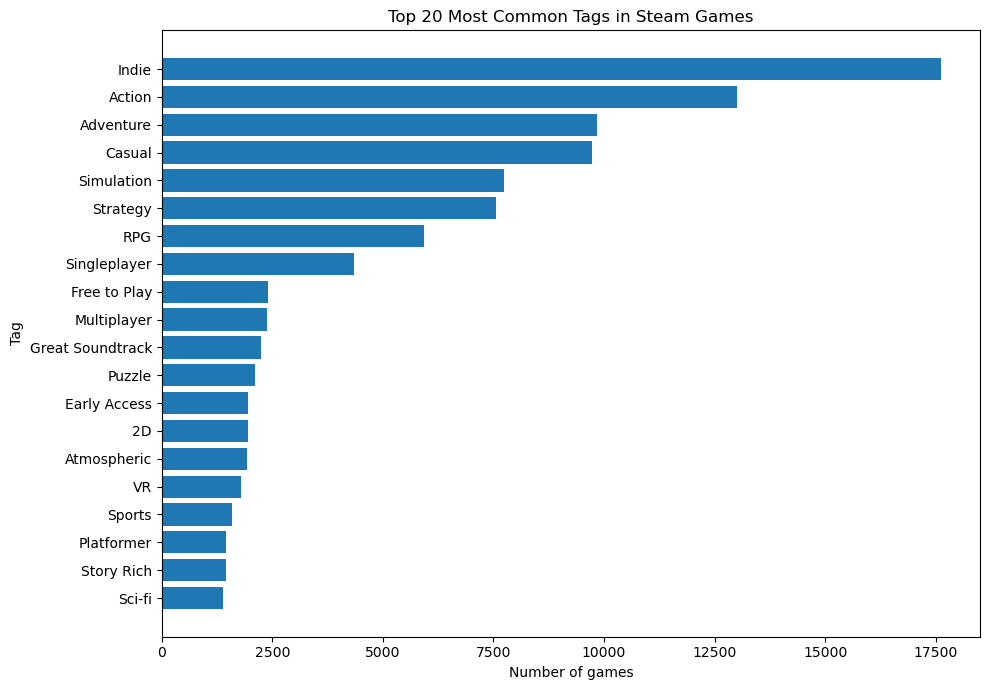

In [ ]:
import matplotlib.pyplot as plt

tag_counts = (
    games_clean["tags"]
    .dropna()
    .explode()
    .value_counts()
)

tags_df = tag_counts.head(20).reset_index()
tags_df.columns = ["tag", "count"]

plt.figure(figsize=(10, 7))
plt.barh(tags_df["tag"][::-1], tags_df["count"][::-1])
plt.xlabel("Number of games")
plt.ylabel("Tag")
plt.title("Top 20 Most Common Tags in Steam Games")
plt.tight_layout()
plt.show()

Count game-name occurrences in user inventories and plot the 20 games listed most often.

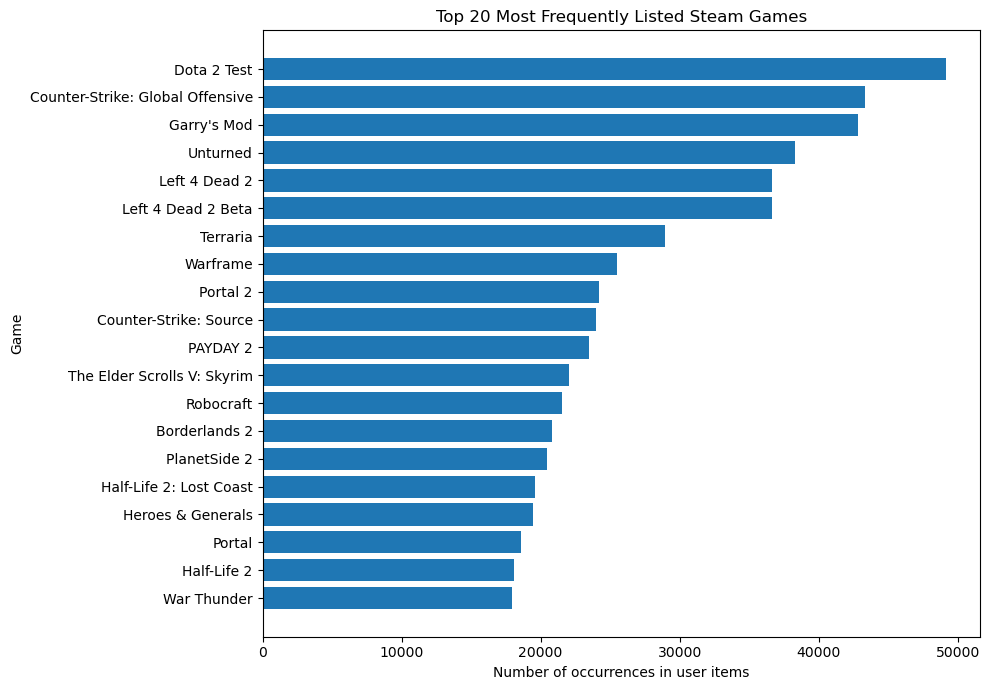

In [168]:
game_counts = user_items_clean["item_name"].dropna().value_counts()

games_df = game_counts.head(20).reset_index()
games_df.columns = ["item_name", "count"]

plt.figure(figsize=(10, 7))
plt.barh(games_df["item_name"][::-1], games_df["count"][::-1])
plt.xlabel("Number of occurrences in user items")
plt.ylabel("Game")
plt.title("Top 20 Most Frequently Listed Steam Games")
plt.tight_layout()
plt.show()